In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import TTestIndPower, TTestPower
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ALPHA = 0.05
rng = np.random.default_rng(2026)

# Chart colors, always in this order: blue, orange, aqua. Gray for reference lines.
C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.dpi": 110,
})

# A/B testing a recommender with MRR

**Scenario:** when a customer opens the app, the recommender shows a ranked list of **K = 10** products. We record where in that list the customer's first relevant product (the one they clicked or bought) appeared.

**RR (reciprocal rank)** of one customer = 1 ÷ the rank of their first relevant product, or 0 if none was in the top 10:

| First relevant product at rank | 1 | 2 | 3 | 4 | 5 | … | 10 | not in top 10 |
|---|---|---|---|---|---|---|---|---|
| RR | 1 | 0.5 | 0.33 | 0.25 | 0.2 | … | 0.1 | 0 |

**MRR (mean reciprocal rank)** = the average RR over customers. It runs from 0 to 1. Higher means relevant products show up nearer the top.

Notice RR drops fast: moving an item from rank 2 to rank 1 adds 0.5, but moving it from rank 10 to rank 9 adds only 0.01. **MRR mostly rewards getting the top spot right.**

The `TRUE_*` constants are the ground truth used to simulate the data. In real life you never see them. Here we use them to check whether each test told the truth.

## How to study this notebook

Same three questions as the binary notebook:

1. **Pick the right test.** Are the arms different customers (independent) or the same customers scored twice (paired)? Is there one value per customer, or many sessions per customer?
2. **Use the right tool.** Do it by hand once to understand it, then use the library call.
3. **Read it the right way.** Significant or not? What do the SE, MoE, CI and p-value say? What is the catch?

## What changes from the binary notebook, and what doesn't

| | Binary (conversion) | MRR |
|---|---|---|
| Value per customer | 0 or 1 | 0, 0.1, 0.11, …, 0.33, 0.5, 1 |
| Spread of one customer (SD) | Follows from the rate: √(p(1−p)) | Must be **measured from the data** |
| Main test | Two-proportion z-test | **Welch's t-test**, with a **bootstrap** CI as a check |
| Effect size for power | Cohen's h (`proportion_effectsize`) | **Cohen's d** = difference ÷ SD |
| **SE, MoE, CI, p-value** | | **Read exactly the same way** |

## Vocabulary

| Term | Meaning |
|---|---|
| **Rank** | Position in the recommended list. 1 = top. |
| **Top-K** | The first K items shown. Here K = 10. |
| **RR / MRR** | See above. |
| **Hit@K** | Share of customers with *any* relevant item in the top K. A 0/1 metric, so the binary notebook's tests apply. |
| **Online test** | Real customers see the recommendations live. Usually one model per customer (A/B). |
| **Offline test** | Both models score the same historical data. No customer sees anything. |
| **Independent samples** | The two arms contain different customers. |
| **Paired samples** | Every customer has a value under **both** models. |
| **Session** | One visit to the app. A customer can have many. |
| **Unit of analysis** | The "one thing" each data point represents in the test. It should match what was randomized (here: the customer). |
| **SD vs SE** | SD = how different customers are from each other. SE = how much the *average* would move if we reran the test. SE = SD ÷ √n. |
| **Welch's t-test** | Compares two averages. Like the z-test, but uses the SDs measured from the data, and doesn't assume both arms have the same SD. |
| **Bootstrap** | Estimate the SE/CI by resampling the data itself many times. No formula needed. |
| **Mann-Whitney U** | Compares which arm *tends to* have higher values. Not the same question as "which has the higher mean". |
| **Wilcoxon signed-rank** | The paired version of a rank-based test. |

## Pick the right test: the map

| Situation | Samples | Test | Tool |
|---|---|---|---|
| Online A/B, different customers per arm, one RR per customer | Independent | Welch's t-test (+ bootstrap CI as a check) | `stats.ttest_ind(equal_var=False)`, `stats.bootstrap` |
| Offline, both models rank the same customers | Paired | Paired t-test (+ Wilcoxon / paired bootstrap as checks) | `stats.ttest_rel`, `stats.wilcoxon` |
| Online, many sessions per customer | Clustered | Average to **one value per customer first**, then Welch | `groupby` + `stats.ttest_ind` |
| Question is "which model *usually* ranks better?", not the mean | Independent | Mann-Whitney U | `stats.mannwhitneyu` |
| Hit@K (0/1) | Independent | Two-proportion z-test | `proportions_ztest` |

# Part A: Mock data

## How the simulation works

Each model has a chance of putting the first relevant item at rank 1, 2, …, 10, or missing it completely. The new model is slightly better at both: it hits a bit more often (41% vs 40%), and when it hits, the item tends to be nearer the top.

In [3]:
K = 10
RR_VALUES = np.append(1 / np.arange(1, K + 1), 0.0)   # ranks 1..10, then "not in top 10"
RANK_LABELS = [f"rank {r}" for r in range(1, K + 1)] + ["miss"]


def rank_probs(hit_rate, decay):
    # Chance of the first relevant item at rank 1..K (decaying with rank), then the chance of a miss
    ranks = np.arange(1, K + 1)
    w = (1 - decay) ** (ranks - 1)
    return np.append(hit_rate * w / w.sum(), 1 - hit_rate)


def draw_rr(probs, u):
    # Turn uniform random numbers u into RR values. Small u = good rank,
    # so giving two models the same u makes their results correlated.
    idx = np.minimum(np.searchsorted(np.cumsum(probs), u), K)
    return RR_VALUES[idx]


OLD_MODEL = rank_probs(hit_rate=0.40, decay=0.30)
NEW_MODEL = rank_probs(hit_rate=0.41, decay=0.33)
TRUE_MRR_OLD = (OLD_MODEL * RR_VALUES).sum()
TRUE_MRR_NEW = (NEW_MODEL * RR_VALUES).sum()
print(f"TRUE MRR old={TRUE_MRR_OLD:.4f}  new={TRUE_MRR_NEW:.4f}  "
      f"diff={TRUE_MRR_NEW - TRUE_MRR_OLD:+.4f} ({TRUE_MRR_NEW / TRUE_MRR_OLD - 1:+.1%})")

pd.DataFrame({"RR": RR_VALUES, "P(old)": OLD_MODEL, "P(new)": NEW_MODEL}, index=RANK_LABELS).round(3).T

TRUE MRR old=0.2115  new=0.2274  diff=+0.0159 (+7.5%)


,rank 1,rank 2,rank 3,rank 4,rank 5,rank 6,rank 7,rank 8,rank 9,rank 10,miss
RR,1.000,0.500,0.333,0.250,0.200,0.167,0.143,0.125,0.111,0.100,0.00
P(old),0.123,0.086,0.061,0.042,0.030,0.021,0.015,0.010,0.007,0.005,0.60
P(new),0.138,0.092,0.062,0.041,0.028,0.019,0.012,0.008,0.006,0.004,0.59


## Case 1: online A/B test, one visit per customer

10,000 customers are randomly split 50/50. Each sees recommendations from one model only, once. One RR per customer.

In [4]:
N_PER_ARM_C1 = 5_000

n = 2 * N_PER_ARM_C1
case1 = pd.DataFrame({
    "customer_id": np.arange(1, n + 1),
    "group": rng.permutation(np.repeat(["control", "treatment"], N_PER_ARM_C1)),
})
case1["model"] = case1["group"].map({"control": "old", "treatment": "new"})
u = rng.random(n)
case1["rr"] = np.where(case1["model"] == "new", draw_rr(NEW_MODEL, u), draw_rr(OLD_MODEL, u))

case1.head()

,customer_id,group,model,rr
0,1,treatment,new,0.000000
1,2,control,old,0.333333
2,3,treatment,new,0.000000
3,4,treatment,new,1.000000
4,5,treatment,new,0.000000


## Case 2: offline evaluation, both models rank the same customers

We take 3,000 customers' most recent purchase from history (held out from training) and ask **both** models to rank products for each customer. Every customer gets **two** RRs: one per model.

Some customers are easy for any model (loyal buyers of one category), others are hard for any model. So a customer's two RRs are **correlated**.

In [5]:
N_C2 = 3_000
SHARED = 0.7   # how often a customer is equally easy (or hard) for both models

u_old = rng.random(N_C2)
u_new = np.where(rng.random(N_C2) < SHARED, u_old, rng.random(N_C2))
case2 = pd.DataFrame({
    "customer_id": np.arange(1, N_C2 + 1),
    "rr_old": draw_rr(OLD_MODEL, u_old),
    "rr_new": draw_rr(NEW_MODEL, u_new),
})

case2.head()

,customer_id,rr_old,rr_new
0,1,0.00,0.000000
1,2,0.25,0.333333
2,3,0.00,0.000000
3,4,0.00,0.000000
4,5,0.00,0.142857


## Case 3: online A/B test, many visits per customer

4,000 customers are randomly split 50/50 (**randomized by customer**). During the test each customer opens the app several times, and **each session** gets its own RR. Most customers visit a few times; heavy users visit 20+ times. A customer's sessions tend to be alike, because their tastes don't change between visits.

In [6]:
N_PER_ARM_C3 = 2_000
SAME_TASTE = 0.6   # chance a session behaves like that customer's "usual" session

n = 2 * N_PER_ARM_C3
customers = pd.DataFrame({
    "customer_id": np.arange(1, n + 1),
    "model": rng.permutation(np.repeat(["old", "new"], N_PER_ARM_C3)),
    "n_sessions": 1 + rng.poisson(rng.exponential(3.0, n)),   # a few visits for most, many for some
    "u_customer": rng.random(n),
})
case3 = customers.loc[customers.index.repeat(customers["n_sessions"])].reset_index(drop=True)
m = len(case3)
u = np.where(rng.random(m) < SAME_TASTE, case3["u_customer"].to_numpy(), rng.random(m))
case3["rr"] = np.where(case3["model"] == "new", draw_rr(NEW_MODEL, u), draw_rr(OLD_MODEL, u))
case3["session"] = case3.groupby("customer_id").cumcount() + 1
case3 = case3[["customer_id", "session", "model", "rr"]]

case3.head(8)

,customer_id,session,model,rr
0,1,1,old,0.0
1,1,2,old,0.0
2,2,1,old,1.0
3,3,1,old,0.0
4,3,2,old,0.0
5,3,3,old,0.0
6,3,4,old,0.0
7,3,5,old,0.2


## Quick look (always look at the data before testing it)

In [7]:
print("Case 1 (one RR per customer)")
print(case1.groupby("model")["rr"].agg(["count", "mean", "std"]).round(4), "\n")
print("Case 2 (two RRs per customer)")
print(case2[["rr_old", "rr_new"]].agg(["count", "mean", "std"]).round(4), "\n")
print("Case 3 (many sessions per customer)")
print(case3.groupby("model").agg(customers=("customer_id", "nunique"), sessions=("rr", "size"),
                                 mrr=("rr", "mean")).round(4), "\n")
print("sessions per customer:", customers["n_sessions"].describe().round(1).to_dict())

Case 1 (one RR per customer)
       count    mean     std
model                       
new     5000  0.2220  0.3413
old     5000  0.2134  0.3335 

Case 2 (two RRs per customer)
          rr_old     rr_new
count  3000.0000  3000.0000
mean      0.2152     0.2278
std       0.3400     0.3466 

Case 3 (many sessions per customer)
       customers  sessions     mrr
model                             
new         2000      7931  0.2304
old         2000      7952  0.1961 

sessions per customer: {'count': 4000.0, 'mean': 4.0, 'std': 3.4, 'min': 1.0, '25%': 1.0, '50%': 3.0, '75%': 5.0, 'max': 31.0}


**What RR data looks like.** Not a bell curve at all: a big spike at 0 (no relevant item in the top 10), a spike at 1, and small bumps at 0.5, 0.33, 0.25 and so on.

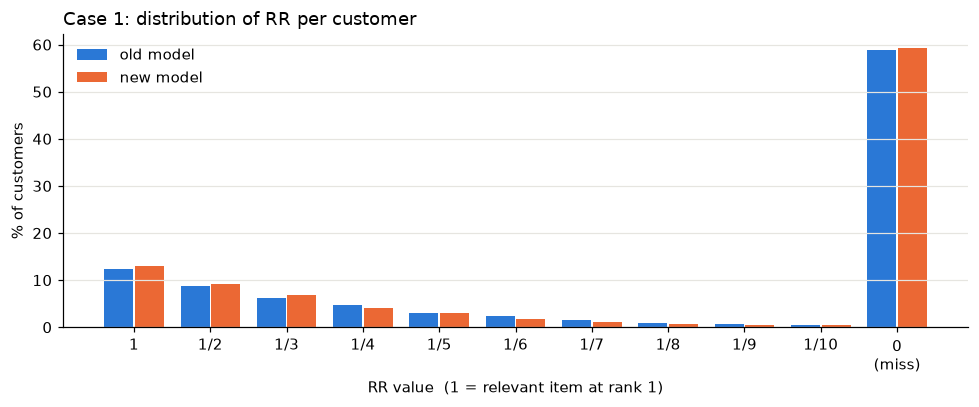

In [8]:
dist = (case1.groupby("model")["rr"].value_counts(normalize=True)
        .unstack("model").reindex(RR_VALUES).fillna(0))
x = np.arange(len(RR_VALUES))
labels = ["1"] + [f"1/{r}" for r in range(2, K + 1)] + ["0\n(miss)"]

fig, ax = plt.subplots(figsize=(9, 3.8))
w = 0.38
ax.bar(x - w / 2 - 0.01, dist["old"] * 100, width=w, color=C_BLUE, label="old model")
ax.bar(x + w / 2 + 0.01, dist["new"] * 100, width=w, color=C_ORANGE, label="new model")
ax.set_xticks(x, labels)
ax.set_xlabel("RR value  (1 = relevant item at rank 1)")
ax.set_ylabel("% of customers")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
ax.set_title("Case 1: distribution of RR per customer", loc="left")
plt.tight_layout()
plt.show()

# Why each test, and the assumptions behind it

Every test makes promises ("5% false alarms", "95% CI") **only if its assumptions hold**. So picking a test means: which question does it answer, and do its assumptions fit my data?

## Design assumptions: behind every test here

These come from how the experiment was run, not from the test. No test can fix them afterwards.

| Assumption | Plain English | Fits our case? |
|---|---|---|
| **Random assignment** | Chance alone decided which customer got which model, so the arms differ only by the model | ✅ Cases 1 and 3 randomize customers. Case 2 needs none: the *same* customers are scored by both models. |
| **Independent units** | One customer's result tells you nothing about another's | ✅ for customers. ❌ for sessions of the same customer (Case 3), which is why we aggregate. |
| **No interference** | Customer A's model doesn't change customer B's result | ✅ assumed. Could break if recommendations change stock or popularity that both arms share. |
| **Stable during the test** | Customers react the same on day 1 as on day 14 | ✅ assumed in the simulation. In real life watch for novelty effects (new lists get clicked more just because they're new). |

## Each test: why we use it and what it assumes

### Welch's t-test (Cases 1 and 3, Problem 4)
**Why:** the business metric is MRR, which is an **average**. Welch's t-test is the standard test for "are two averages different?" between two independent groups.

| Assumption | Fits our case? |
|---|---|
| Two **independent** groups of units | ✅ different customers in each arm |
| The **average** is roughly a bell curve. Raw data does **not** need to be. | ✅ thousands of customers per arm. Problem 2 shows it works from about 30 per arm. |
| No big outliers that dominate the average | ✅ RR can only be between 0 and 1, so no customer can dominate |
| Equal SDs in both arms | **Not needed.** That's why we use Welch rather than Student's t-test. (Ours are close anyway: 0.334 vs 0.341.) |

### Bootstrap (Case 1 check, Case 2 paired version)
**Why:** a check that needs **no formula and no bell-curve assumption**. It's useful because RR looks nothing like a bell curve, and it works for any metric.

| Assumption | Fits our case? |
|---|---|
| The sample looks like the population (it's large and was randomly drawn) | ✅ 5,000 customers per arm |
| You resample the **independent unit**: customers, not sessions | ✅ customers in Case 1. In Case 2 we resample customers *with both their RRs*. |
| Percentile CI: the bootstrap distribution is roughly symmetric | ✅ see the bootstrap chart |

### Paired t-test (Case 2)
**Why:** both models scored the **same** customers. Comparing each customer with themselves removes the "easy vs hard customer" noise, which halves the SE.

| Assumption | Fits our case? |
|---|---|
| Every value under model A has a matching value under model B (same customer) | ✅ every customer has `rr_old` and `rr_new` |
| Customers (pairs) are independent of each other | ✅ |
| The **average difference** is roughly a bell curve | ✅ 3,000 differences. Raw differences are spiky (72% are 0), but the average is fine. |

### Wilcoxon signed-rank (Case 2, side check only)
**Why it's in the notebook:** it's the textbook "non-parametric paired test", so you will be asked about it.

| Assumption | Fits our case? |
|---|---|
| Paired data | ✅ |
| Differences are spread **symmetrically** around their center | ⚠️ Roughly (skewness −0.28), but they take only a few lumpy values |
| Few zero differences and few ties | ❌ 72% of differences are exactly 0 and get **dropped** |
| You care about the **typical** difference, not the average | ❌ MRR is an average |

→ **Not the right test for MRR.** Use it only as a side check.

### Mann-Whitney U (Problem 4)
**Why it's in the notebook:** people often use it as a "t-test for non-normal data". Problem 4 shows why that's a mistake.

| Assumption | Fits our case? |
|---|---|
| Two independent groups | ✅ |
| It tests "is a random customer from A more likely to beat one from B?" It only equals "the means differ" if both distributions have the **same shape** | ❌ RR distributions can have different shapes (steady vs hit-or-miss) |
| Few ties | ❌ about 60% of RRs are exactly 0 |

→ **Not the right test for MRR.** Use it only when the question really is "which model does the *typical* customer prefer?"

### Two-proportion z-test (Problem 5, hit@10)
**Why:** hit@10 is 0/1 per customer, the same situation as the binary notebook.

| Assumption | Fits our case? |
|---|---|
| Independent customers with a 0/1 outcome | ✅ |
| Enough hits **and** misses in each arm (rule of thumb ≥ 10 each) | ✅ about 2,000 of each per arm |

### Aggregate to one value per customer, then Welch (Case 3)
**Why:** we randomized **customers**, so customers are the independent units. Averaging each customer's sessions gives one independent number per customer.

| Assumption | Fits our case? |
|---|---|
| Randomized by customer, and customers are independent | ✅ |
| Each customer counts once, whether they had 1 session or 30 | ✅ if the business means **customer-weighted** MRR. For session-weighted MRR, use a cluster bootstrap instead. |
| Enough customers for the average to be a bell curve | ✅ 2,000 per arm |

### Power analysis (Problem 1: `TTestIndPower`, `TTestPower`)
**Why:** decide the sample size **before** the test, so a lift worth having isn't missed (as happened in Case 1).

| Assumption | Fits our case? |
|---|---|
| The SD you plug in is right | ⚠️ Measured from history/pilot (0.334). Re-measure if the product or K changes. |
| The MDE is the smallest lift the business cares about | ⚠️ A business decision. We used +7.5%. |
| Same bell-curve approximation as the t-test | ✅ |

## Check the assumptions on our data

In [9]:
d2 = (case2["rr_new"] - case2["rr_old"]).to_numpy()
sessions_per_customer = case3.groupby("customer_id").size()
hits_per_arm = case1.assign(hit=case1["rr"] > 0).groupby("model")["hit"].agg(["sum", "size"])

checks = [
    ("Welch", "customers in smallest arm (Case 1)", case1["model"].value_counts().min(), ">= 30 (CLT, Problem 2)"),
    ("Welch", "RR range (Case 1)", f"{case1['rr'].min():.0f} to {case1['rr'].max():.0f}", "bounded -> no extreme outliers"),
    ("Welch", "SD ratio old / new (Case 1)",
     round(case1.loc[case1['model'] == 'old', 'rr'].std() / case1.loc[case1['model'] == 'new', 'rr'].std(), 3),
     "any value is fine for Welch"),
    ("Paired t", "customers with both RRs (Case 2)", int(case2[["rr_old", "rr_new"]].notna().all(axis=1).sum()), "every row paired"),
    ("Paired t", "correlation of a customer's two RRs", round(np.corrcoef(case2["rr_old"], case2["rr_new"])[0, 1], 2),
     "> 0 -> pairing reduces SE"),
    ("Wilcoxon", "share of zero differences (dropped)", f"{(d2 == 0).mean():.0%}", "small, ideally"),
    ("Wilcoxon", "skewness of non-zero differences", round(stats.skew(d2[d2 != 0]), 2), "near 0 = symmetric"),
    ("Mann-Whitney", "share of RR = 0 (ties, Case 1)", f"{(case1['rr'] == 0).mean():.0%}", "small, ideally"),
    ("Case 3", "sessions per customer: median / max", f"{sessions_per_customer.median():.0f} / {sessions_per_customer.max()}",
     "> 1 -> sessions not independent"),
    ("Case 3", "customers in smallest arm", customers["model"].value_counts().min(), ">= 30"),
    ("z-test (hit@10)", "fewest hits or misses in an arm",
     int(min(hits_per_arm["sum"].min(), (hits_per_arm["size"] - hits_per_arm["sum"]).min())), ">= 10"),
]
pd.DataFrame(checks, columns=["test", "check", "our value", "what we need"])

,test,check,our value,what we need
0,Welch,customers in smallest arm (Case 1),5000,">= 30 (CLT, Problem 2)"
1,Welch,RR range (Case 1),0 to 1,bounded -> no extreme outliers
2,Welch,SD ratio old / new (Case 1),0.977,any value is fine for Welch
3,Paired t,customers with both RRs (Case 2),3000,every row paired
4,Paired t,correlation of a customer's two RRs,0.71,> 0 -> pairing reduces SE
5,Wilcoxon,share of zero differences (dropped),72%,"small, ideally"
6,Wilcoxon,skewness of non-zero differences,-0.28,near 0 = symmetric
7,Mann-Whitney,"share of RR = 0 (ties, Case 1)",59%,"small, ideally"
8,Case 3,sessions per customer: median / max,3 / 31,> 1 -> sessions not independent
9,Case 3,customers in smallest arm,2000,>= 30


**Reading the checks:** everything the Welch, paired t and z-tests need is in place. The Wilcoxon and Mann-Whitney checks show heavy ties: 72% zero differences and 59% zero RRs. The non-zero differences are roughly symmetric, so that part is fine. That's another reason they're side checks here, not the main test. Case 3's repeated sessions confirm we must aggregate to customers before testing.

## The key idea for MRR

**"My data isn't normal" is not a reason to switch tests.** The t-test needs the **average** to be bell-shaped, and with thousands of customers it is (Problem 2). For MRR, the assumptions that actually break are about **independence** (sessions, Case 3) and **pairing** (offline, Case 2), not normality.

So before picking a test, ask these three questions in order:

1. **Who did I randomize?** → That's my unit. Aggregate the data to one value per unit.
2. **Are the same units measured under both models?** → Yes: paired test. No: independent test.
3. **Is my question about the average (MRR) or the typical customer?** → Average: Welch / paired t (bootstrap as a check). Typical customer: Mann-Whitney / Wilcoxon.

# Part B: Testing each case

## Case 1 test: Welch's t-test

**Pick:** two different groups of customers, one RR each, and we compare the **average** (MRR) → **Welch's t-test**.

**Why it is OK even though RR is not a bell curve:** the test is about the *average* of thousands of customers, and averages of many values are close to a bell curve whatever the raw data looks like. This is the **central limit theorem**. Problem 2 checks it by simulation.

**Same idea as the z-test:** t = difference ÷ SE. Two small differences:
- The SD isn't given by a formula like √(p(1−p)). It is **measured from the data**.
- The cutoff comes from the **t-distribution** instead of the normal curve. With small samples it is a bit stricter. With thousands of customers it is ≈ 1.96 anyway.

"Welch" = the version that does **not** assume both arms have the same SD. It's the safe default; the old "Student's" t-test assumes equal SDs.

In [10]:
new = case1.loc[case1["model"] == "new", "rr"].to_numpy()
old = case1.loc[case1["model"] == "old", "rr"].to_numpy()
n_new, n_old = len(new), len(old)
diff = new.mean() - old.mean()

# SD per customer, measured from the data
sd_new, sd_old = new.std(ddof=1), old.std(ddof=1)
se = np.sqrt(sd_new ** 2 / n_new + sd_old ** 2 / n_old)
t = diff / se

# Welch-Satterthwaite degrees of freedom: how "sure" we are about the SDs themselves
df = se ** 4 / ((sd_new ** 2 / n_new) ** 2 / (n_new - 1) + (sd_old ** 2 / n_old) ** 2 / (n_old - 1))
p_value = 2 * stats.t.sf(abs(t), df)
t_crit = stats.t.ppf(1 - ALPHA / 2, df)   # ~1.96 with this many customers
moe = t_crit * se

print(f"MRR old={old.mean():.4f}  new={new.mean():.4f}  diff={diff:+.4f} ({diff / old.mean():+.1%} relative)")
print(f"SD old={sd_old:.4f}  SD new={sd_new:.4f}")
print(f"SE={se:.5f}  t={t:.3f}  df={df:.0f}  p-value={p_value:.5f}")
print(f"MoE=±{moe:.4f}  95% CI for diff: [{diff - moe:+.4f}, {diff + moe:+.4f}]")
print(f"truth: diff={TRUE_MRR_NEW - TRUE_MRR_OLD:+.4f}")

MRR old=0.2134  new=0.2220  diff=+0.0086 (+4.0% relative)
SD old=0.3335  SD new=0.3413
SE=0.00675  t=1.272  df=9993  p-value=0.20355
MoE=±0.0132  95% CI for diff: [-0.0046, +0.0218]
truth: diff=+0.0159


Library version, which should match:

In [11]:
res = stats.ttest_ind(new, old, equal_var=False)   # equal_var=False -> Welch
ci = res.confidence_interval(confidence_level=0.95)
print(f"t={res.statistic:.3f}  p-value={res.pvalue:.5f}  95% CI: [{ci.low:+.4f}, {ci.high:+.4f}]")

t=1.272  p-value=0.20355  95% CI: [-0.0046, +0.0218]


The same steps wrapped in a function, so the rest of the notebook can reuse them:

In [12]:
def welch_test(a, b, alpha=ALPHA):
    # Welch's t-test for mean(a) - mean(b), with its CI
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    res = stats.ttest_ind(a, b, equal_var=False)
    ci = res.confidence_interval(confidence_level=1 - alpha)
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return pd.Series({
        "n_a": len(a), "n_b": len(b), "mean_a": a.mean(), "mean_b": b.mean(),
        "diff": a.mean() - b.mean(), "se": se, "t": res.statistic, "p_value": res.pvalue,
        "ci_low": ci.low, "ci_high": ci.high, "significant": res.pvalue < alpha,
    })


welch_test(new, old)

n_a                5000
n_b                5000
mean_a         0.222031
mean_b          0.21345
diff           0.008582
se             0.006749
t              1.271591
p_value        0.203548
ci_low        -0.004647
ci_high         0.02181
significant       False
dtype: object

### Check with the bootstrap

**Idea in plain English:** we can't rerun the experiment, so we fake reruns from the data we have. Draw 5,000 customers *with replacement* from each arm (some customers get picked twice, some not at all), compute the MRR difference, and repeat 5,000 times. The spread of those 5,000 differences is the SE; the middle 95% is the CI.

**Why it's useful:** no formula and no bell-curve assumption. It works for any metric (median, ratios, anything), so it's the universal check when you're not sure a formula applies.

bootstrap SE=0.00677   (Welch SE=0.00675)
bootstrap 95% CI: [-0.0049, +0.0216]


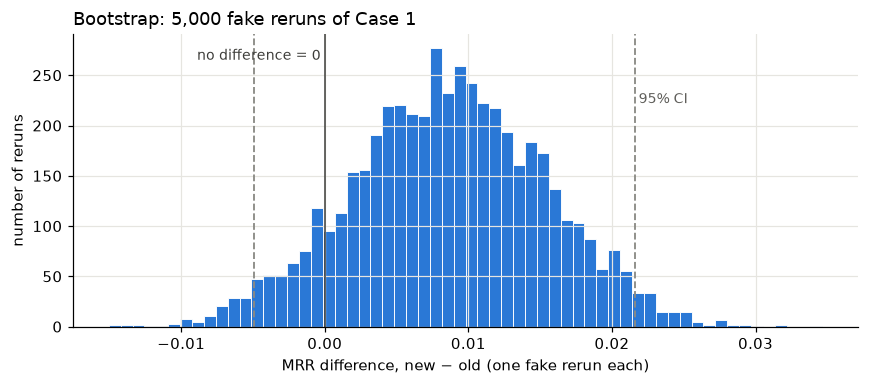

In [13]:
boot = stats.bootstrap(
    (new, old), lambda a, b, axis: a.mean(axis=axis) - b.mean(axis=axis),
    n_resamples=5_000, method="percentile", batch=250, rng=np.random.default_rng(1),
)
print(f"bootstrap SE={boot.standard_error:.5f}   (Welch SE={se:.5f})")
print(f"bootstrap 95% CI: [{boot.confidence_interval.low:+.4f}, {boot.confidence_interval.high:+.4f}]")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(boot.bootstrap_distribution, bins=60, color=C_BLUE, edgecolor="white", linewidth=0.6)
for v in (boot.confidence_interval.low, boot.confidence_interval.high):
    ax.axvline(v, color=C_GRAY, linestyle="--", linewidth=1.2)
ax.axvline(0, color="#3d3d3a", linewidth=1)
ax.text(0, ax.get_ylim()[1] * 0.95, "no difference = 0 ", fontsize=9, color="#3d3d3a", va="top", ha="right")
ax.text(boot.confidence_interval.high, ax.get_ylim()[1] * 0.80, " 95% CI", fontsize=9, color="#5f5e5a", va="top")
ax.set_xlabel("MRR difference, new − old (one fake rerun each)")
ax.set_ylabel("number of reruns")
ax.set_title("Bootstrap: 5,000 fake reruns of Case 1", loc="left")
plt.tight_layout()
plt.show()

### Case 1 conclusion: ❌ not significant (a real lift was missed)

| | Value | What it tells us |
|---|---|---|
| Observed diff | **+0.0086** (MRR 0.2134 → 0.2220, +4.0% relative) | The raw gap |
| SD per customer | about 0.33 | Customers differ a lot: most have RR 0, some have 1 |
| SE | 0.0068 | A rerun would typically move the gap by about ±0.007 |
| t | 1.27 | Only 1.3 wobbles from 0. Luck explains this easily. |
| p-value | 0.20 | With no real difference, a gap this big happens 1 time in 5 |
| MoE | ±0.0132 | Bigger than the gap itself → could be 0 |
| 95% CI | [−0.0046, +0.0218] | Includes 0 → not significant. Also includes the truth (+0.0159). |
| Bootstrap | SE 0.0068, CI [−0.0049, +0.0216] | Matches Welch. The formula is trustworthy here. |

**Decision:** no evidence the new recommender is better. That is **not** proof it's no better: the CI reaches +0.022, a +10% lift.

**The catch:**
1. **The test was too small.** The truth is +0.0159 (+7.5%), but this test only had a 67% chance to detect it (Problem 1). It needed about 6,800 customers per arm; it had 5,000. Same story as Case 2.1 in the binary notebook.
2. **The raw data isn't a bell curve and that's fine.** The test is about the *average* of 5,000 customers, which is close to a bell curve (Problem 2). The bootstrap, which assumes nothing about shape, agrees with Welch.
3. **Watch the units.** MRR differences are small numbers like 0.0086. Always also report the **relative** lift (+4.0%), which the business understands.

## Case 2 test: paired t-test (offline evaluation)

**Pick:** the *same* customers are scored by both models → **paired**. The right question is "for each customer, how much better is the new model?" So compute **one difference per customer** and test whether the average difference is 0.

First the **wrong** way (pretending the two columns are different customers), then the right way.

In [14]:
wrong = welch_test(case2["rr_new"], case2["rr_old"])

# Right: one difference per customer, then a one-sample t-test on the differences
d = (case2["rr_new"] - case2["rr_old"]).to_numpy()
n = len(d)
se_paired = d.std(ddof=1) / np.sqrt(n)
t_paired = d.mean() / se_paired
p_paired = 2 * stats.t.sf(abs(t_paired), n - 1)
moe_paired = stats.t.ppf(1 - ALPHA / 2, n - 1) * se_paired

print(f"correlation between a customer's two RRs: {np.corrcoef(case2['rr_old'], case2['rr_new'])[0, 1]:.2f}")
print(f"customers with the same RR under both models: {(d == 0).mean():.0%}\n")
pd.DataFrame({
    "wrong: Welch (independent)": [wrong["diff"], wrong["se"], wrong["t"], wrong["p_value"],
                                   wrong["ci_low"], wrong["ci_high"]],
    "right: paired": [d.mean(), se_paired, t_paired, p_paired, d.mean() - moe_paired, d.mean() + moe_paired],
}, index=["diff", "SE", "t", "p_value", "ci_low", "ci_high"]).round(5)

correlation between a customer's two RRs: 0.71
customers with the same RR under both models: 72%



,wrong: Welch (independent),right: paired
diff,0.01261,0.01261
SE,0.00887,0.00480
t,1.42290,2.62610
p_value,0.15482,0.00868
ci_low,-0.00476,0.00320
ci_high,0.02999,0.02203


Library versions and two checks:

In [15]:
res = stats.ttest_rel(case2["rr_new"], case2["rr_old"])
ci = res.confidence_interval(confidence_level=0.95)
print(f"paired t-test:     t={res.statistic:.3f}  p={res.pvalue:.6f}  CI=[{ci.low:+.4f}, {ci.high:+.4f}]")

# Wilcoxon signed-rank: rank-based check. Drops customers whose difference is exactly 0.
w = stats.wilcoxon(case2["rr_new"], case2["rr_old"])
print(f"Wilcoxon:          p={w.pvalue:.6f}")

# Paired bootstrap: resample customers (each keeps both of their RRs)
boot_p = stats.bootstrap((d,), np.mean, n_resamples=5_000, method="percentile", rng=np.random.default_rng(2))
print(f"paired bootstrap:  SE={boot_p.standard_error:.5f}  "
      f"CI=[{boot_p.confidence_interval.low:+.4f}, {boot_p.confidence_interval.high:+.4f}]")
print(f"truth: diff={TRUE_MRR_NEW - TRUE_MRR_OLD:+.4f}")

paired t-test:     t=2.626  p=0.008681  CI=[+0.0032, +0.0220]
Wilcoxon:          p=0.000000
paired bootstrap:  SE=0.00477  CI=[+0.0034, +0.0219]
truth: diff=+0.0159


### Case 2 conclusion: ✅ significant with the paired test (❌ with the wrong test)

| | Wrong: Welch (independent) | Right: paired t-test |
|---|---|---|
| diff | +0.0126 | +0.0126 (the same) |
| SE | 0.0089 | **0.0048** (almost half) |
| t | 1.42 | 2.63 |
| p-value | 0.155 ❌ | **0.0087** ✅ |
| 95% CI | [−0.0048, +0.0300] | [+0.0032, +0.0220] |

The paired bootstrap agrees (SE 0.0048, CI [+0.0034, +0.0219]). The truth (+0.0159) is inside the paired CI.

**Why pairing helps:** a customer's two RRs are strongly linked (correlation 0.71). Easy customers are easy for both models, hard ones are hard for both. The paired test compares each customer **with themselves**, so the "easy vs hard customer" noise cancels out. Only the model difference is left. Same data, same difference, but half the SE.

**Decision:** offline, the new model ranks better: +0.003 to +0.022 MRR.

**The catch:**
1. **Using an independent test on paired data throws away evidence.** It isn't wrong in the "false alarm" sense; it's wastefully cautious. Here it turned a real win into "not significant".
2. **Wilcoxon's p ≈ 0 does not mean "even stronger evidence".** It drops the 72% of customers whose two RRs are equal (mostly both 0), and it asks a different question: among customers where the models differ, does the new one *usually* win? Report the paired t-test (or paired bootstrap) for MRR.
3. **Offline ≠ online.** Offline uses past purchases, made while customers were seeing the *old* recommendations. Customers don't react to the new list. An offline win is a good reason to run an online A/B test, not a replacement for it.

## Case 3 test: many sessions per customer

**Pick:** we randomized **customers**, but the data has one row per **session**. Sessions from the same customer are alike, so they are not independent pieces of evidence. 20 sessions from one heavy user are closer to "one customer, measured 20 times" than to "20 customers".

- **Wrong:** Welch's t-test on all sessions, as if each were a separate customer.
- **Right:** first average each customer's sessions into **one RR per customer**, then Welch's t-test on customers. This matches the unit of analysis to the unit of randomization.

In [16]:
wrong = welch_test(case3.loc[case3["model"] == "new", "rr"], case3.loc[case3["model"] == "old", "rr"])

per_customer = case3.groupby(["customer_id", "model"], as_index=False)["rr"].mean()
right = welch_test(per_customer.loc[per_customer["model"] == "new", "rr"],
                   per_customer.loc[per_customer["model"] == "old", "rr"])

pd.DataFrame({"wrong: sessions as units": wrong, "right: one value per customer": right}).drop("significant").astype(float).round(5)

,wrong: sessions as units,right: one value per customer
n_a,7931.00000,2000.00000
n_b,7952.00000,2000.00000
mean_a,0.23037,0.22812
mean_b,0.19609,0.20542
diff,0.03428,0.02270
se,0.00527,0.00865
t,6.50109,2.62497
p_value,0.00000,0.00870
ci_low,0.02394,0.00575
ci_high,0.04462,0.03966


**Two different MRRs.** Session-level MRR lets heavy users count once per visit. Customer-level MRR counts every customer once. They answer different questions ("average experience per visit" vs "average experience per customer"), and they can differ. Decide which one the business means **before** the test.

In [17]:
for label, df_ in [("session-weighted MRR", case3), ("customer-weighted MRR", per_customer)]:
    print(f"{label:<22}: " + "  ".join(f"{m}={df_.loc[df_['model'] == m, 'rr'].mean():.4f}" for m in ["old", "new"]))

session-weighted MRR  : old=0.1961  new=0.2304
customer-weighted MRR : old=0.2054  new=0.2281


### Case 3 conclusion: ✅ significant at customer level, but the session-level answer was misleading

| | Wrong: sessions as units | Right: one value per customer |
|---|---|---|
| Data points | 15,883 sessions | 4,000 customers |
| diff | +0.0343 | +0.0227 |
| SE | 0.0053 | **0.0087** (1.6× larger) |
| t | 6.50 | 2.62 |
| p-value | 0.0000001 | 0.0087 |
| 95% CI | [+0.0239, +0.0446] | [+0.0058, +0.0397] |
| Contains the truth (+0.0159)? | **No** ❌ | Yes ✅ |

**Decision:** the new model is better at customer level, plausibly +0.006 to +0.040 MRR.

**What went wrong with sessions as units:**
1. **The SE was too small.** It assumed 15,883 independent pieces of evidence. But a heavy user's 20 similar sessions are closer to *one* piece of evidence repeated 20 times. Overconfident SE → p-values far too small → false alarms. Problem 3 shows the A/A false positive rate jumps from 5% to about 26%.
2. **The estimate was pulled by heavy users.** A few heavy users in one arm with unusually good (or bad) sessions move the session-level average a lot. Here it overstated the lift (+0.034 vs truth +0.016), and its CI missed the truth entirely.

**The catch:**
1. **Rule: analyse at the level you randomized.** Randomized customers → one number per customer. If you randomized sessions (each visit gets a random model), sessions would be the right unit.
2. **Session-weighted vs customer-weighted MRR are different metrics** (old 0.196 vs 0.205 here). Agree with the business which one counts *before* the test.
3. If you really need the session-weighted metric, keep sessions but get the SE from a **cluster bootstrap** (resample whole customers, with all their sessions) or the **delta method**. Never from the plain t-test on sessions.

# Part C: Problems

## Problem 1: Power and sample size for MRR

Same four knobs as the binary notebook (α, power, baseline, MDE). One difference: for averages, the "how noisy is one customer" number is the **SD**, and you have to **measure it** from historical data or a pilot. It doesn't follow from the rate.

**Effect size = Cohen's d = MDE ÷ SD.** This plays the same role as `proportion_effectsize` in the binary notebook: "how big the change is compared to the noise".

n per arm ≈ 2 × (z₁₋α/₂ + z_power)² × SD² ÷ MDE²

For a **paired** (offline) test, use the SD of the per-customer **differences** instead, and drop the 2.

In [18]:
sd_hist = case1.loc[case1["model"] == "old", "rr"].std()                   # "historical" SD of RR
sd_diff = (case2["rr_new"] - case2["rr_old"]).std()                        # SD of paired differences
mde = 0.016                                                                # about +7.5% relative

d_ind = mde / sd_hist
d_pair = mde / sd_diff
z_sum = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(0.80)
print(f"SD of RR = {sd_hist:.3f}   SD of paired differences = {sd_diff:.3f}")
print(f"Cohen's d: independent={d_ind:.4f}  paired={d_pair:.4f}\n")
print(f"independent, by hand : n per arm = {2 * z_sum ** 2 * sd_hist ** 2 / mde ** 2:,.0f}")
print(f"independent, library : n per arm = {TTestIndPower().solve_power(effect_size=d_ind, alpha=ALPHA, power=0.80, ratio=1):,.0f}")
print(f"paired, library      : n customers = {TTestPower().solve_power(effect_size=d_pair, alpha=ALPHA, power=0.80):,.0f}")
print(f"\npower of Case 1 (5k per arm) : {TTestIndPower().power(effect_size=d_ind, nobs1=5_000, alpha=ALPHA, ratio=1):.0%}")
print(f"power of Case 2 (3k paired)  : {TTestPower().power(effect_size=d_pair, nobs=3_000, alpha=ALPHA):.0%}")

SD of RR = 0.334   SD of paired differences = 0.263
Cohen's d: independent=0.0480  paired=0.0608

independent, by hand : n per arm = 6,820
independent, library : n per arm = 6,821
paired, library      : n customers = 2,124

power of Case 1 (5k per arm) : 67%
power of Case 2 (3k paired)  : 91%


**Planning table for the business** (old MRR ≈ 0.21, 2,000 customers a day split 50/50):

In [19]:
CUSTOMERS_PER_DAY = 2_000
baseline = case1.loc[case1["model"] == "old", "rr"].mean()

rows = []
for rel in [0.03, 0.05, 0.075, 0.10, 0.15]:
    lift = baseline * rel
    n_arm = int(np.ceil(TTestIndPower().solve_power(effect_size=lift / sd_hist, alpha=ALPHA, power=0.80, ratio=1)))
    rows.append({
        "we want to detect": f"MRR {baseline:.3f} -> {baseline + lift:.3f}",
        "relative lift": f"+{rel:.1%}",
        "Cohen's d": round(lift / sd_hist, 4),
        "customers per arm": f"{n_arm:,}",
        "days to run (online)": int(np.ceil(2 * n_arm / CUSTOMERS_PER_DAY)),
    })
pd.DataFrame(rows)

,we want to detect,relative lift,Cohen's d,customers per arm,days to run (online)
0,MRR 0.213 -> 0.220,+3.0%,0.0192,"42,582",43
1,MRR 0.213 -> 0.224,+5.0%,0.0320,"15,330",16
2,MRR 0.213 -> 0.229,+7.5%,0.0480,"6,814",7
3,MRR 0.213 -> 0.235,+10.0%,0.0640,"3,834",4
4,MRR 0.213 -> 0.245,+15.0%,0.0960,"1,705",2


### Problem 1 conclusion

| | Value |
|---|---|
| SD of one customer's RR | 0.334 |
| SD of a customer's paired difference | 0.263 (smaller, because the shared "easy/hard" part cancels) |
| Online, independent: customers per arm for +0.016 (+7.5%) | **6,820** (13,640 total) |
| Offline, paired: customers for the same lift | **2,124** total |
| Power Case 1 had (5k per arm) | 67% → explains why it missed |
| Power Case 2 had (3k paired) | 91% → explains why it found it |

**What this teaches:**
1. **Cohen's d is the "average" version of `proportion_effectsize`:** effect ÷ noise. You must measure the noise (SD) from history or a pilot.
2. **Paired designs are much cheaper.** About 6× fewer customers here. That's why offline evaluation is the standard first filter.
3. **Same rule as before:** halving the lift needs about 4× the customers (+7.5% → 7 days, +3% → 43 days in the planning table).

**The catch:** the SD of RR depends on how often customers get *any* hit. If the product, traffic or K changes, re-measure it. And the paired SD depends on how correlated the two models are, which you only know after scoring both.

## Problem 2: Is a t-test OK when RR is clearly not a bell curve?

Run thousands of **A/A tests** (both arms use the old model) at different sample sizes. If Welch's t-test is trustworthy, about 5% should come out "significant". Also look at how the **average** RR of a sample is distributed as n grows.

In [20]:
p2_rng = np.random.default_rng(3)
N_SIMS = 4_000
rows = []
for n_arm in [10, 30, 100, 1_000]:
    a = draw_rr(OLD_MODEL, p2_rng.random((N_SIMS, n_arm)))
    b = draw_rr(OLD_MODEL, p2_rng.random((N_SIMS, n_arm)))
    with np.errstate(invalid="ignore", divide="ignore"):
        p = stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue
    p = np.nan_to_num(p, nan=1.0)   # both arms all zeros -> no evidence
    rows.append({"customers per arm": n_arm, "false positive rate": (p < ALPHA).mean()})
pd.DataFrame(rows).round(3)

,customers per arm,false positive rate
0,10,0.034
1,30,0.052
2,100,0.050
3,1000,0.050


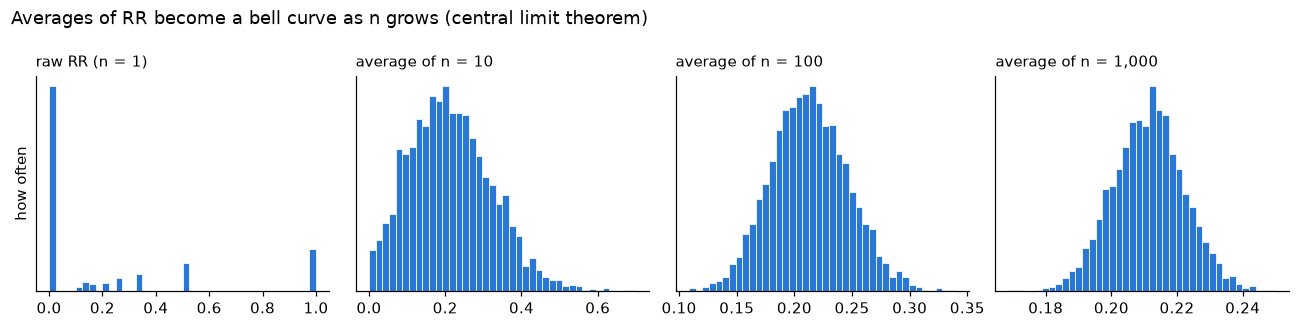

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=False)
for ax, n_arm in zip(axes, [1, 10, 100, 1_000]):
    means = draw_rr(OLD_MODEL, p2_rng.random((N_SIMS, n_arm))).mean(axis=1)
    bins = np.linspace(0, 1, 41) if n_arm == 1 else 40
    ax.hist(means, bins=bins, color=C_BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title("raw RR (n = 1)" if n_arm == 1 else f"average of n = {n_arm:,}", loc="left", fontsize=10)
    ax.set_yticks([])
    ax.grid(visible=False)
axes[0].set_ylabel("how often")
fig.suptitle("Averages of RR become a bell curve as n grows (central limit theorem)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Problem 2 conclusion

| Customers per arm | A/A false positive rate |
|---|---|
| 10 | 3.4% |
| 30 | 5.2% |
| 100 | 5.0% |
| 1,000 | 5.0% |

From about 30 customers per arm, Welch's t-test keeps its 5% promise even though raw RR is spiky and lopsided. The chart shows why: the **average** of 100 or 1,000 RRs is a smooth bell curve.

**What this teaches:** the t-test needs the *average* to be roughly bell-shaped, not the raw data. "My data isn't normal" is **not** a reason to switch tests when n is large.

**The catch:**
1. At **very small n** (10 here) the average is still lopsided, and many samples are all zeros. Results are unreliable (here slightly too cautious). Use more customers, or check with a bootstrap.
2. The rarer the hits (e.g. 99% zeros), the more customers you need before the average becomes bell-shaped. When unsure, run an A/A simulation like this one on your own data.

## Problem 3: Proof for Case 3, what goes wrong when sessions are treated as customers

Run 1,000 **A/A tests** shaped like Case 3 (customers with many similar sessions, both arms on the old model). Count how often each method wrongly says "significant".

sessions as units (wrong)         0.256
one value per customer (right)    0.042
dtype: float64


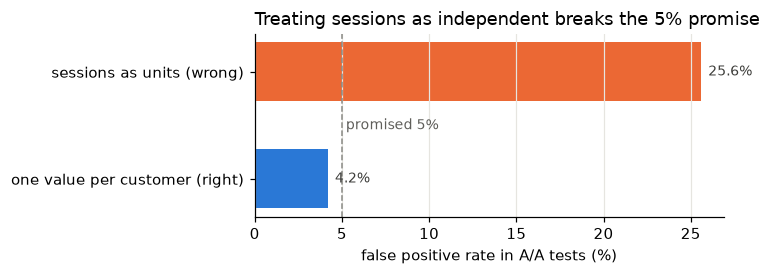

In [22]:
p3_rng = np.random.default_rng(4)
n_customers = 2 * N_PER_ARM_C3
fp_sessions, fp_customers = [], []
for _ in range(1_000):
    n_sess = 1 + p3_rng.poisson(p3_rng.exponential(3.0, n_customers))
    arm = p3_rng.permutation(np.repeat([0, 1], N_PER_ARM_C3))
    cust_of_session = np.repeat(np.arange(n_customers), n_sess)
    u_cust = p3_rng.random(n_customers)[cust_of_session]
    u = np.where(p3_rng.random(len(cust_of_session)) < SAME_TASTE, u_cust, p3_rng.random(len(cust_of_session)))
    rr = draw_rr(OLD_MODEL, u)                                       # A/A: same model in both arms
    arm_s = arm[cust_of_session]
    fp_sessions.append(stats.ttest_ind(rr[arm_s == 1], rr[arm_s == 0], equal_var=False).pvalue < ALPHA)
    rr_cust = np.bincount(cust_of_session, weights=rr) / n_sess      # one average per customer
    fp_customers.append(stats.ttest_ind(rr_cust[arm == 1], rr_cust[arm == 0], equal_var=False).pvalue < ALPHA)

fp = pd.Series({"sessions as units (wrong)": np.mean(fp_sessions),
                "one value per customer (right)": np.mean(fp_customers)})
print(fp.round(3))

fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(fp))[::-1]
ax.barh(y, fp.values * 100, color=[C_ORANGE, C_BLUE], height=0.55)
ax.axvline(ALPHA * 100, color=C_GRAY, linestyle="--", linewidth=1)
ax.text(ALPHA * 100, 0.5, " promised 5%", color="#5f5e5a", fontsize=9, va="center")
for yi, v in zip(y, fp.values):
    ax.text(v * 100 + 0.4, yi, f"{v:.1%}", va="center", fontsize=9, color="#3d3d3a")
ax.set_yticks(y, fp.index)
ax.set_xlabel("false positive rate in A/A tests (%)")
ax.grid(axis="y", visible=False)
ax.set_title("Treating sessions as independent breaks the 5% promise", loc="left")
plt.tight_layout()
plt.show()

### Problem 3 conclusion

| Method | False positive rate (A/A) |
|---|---|
| Sessions as units | **25.6%** |
| One value per customer | 4.2% |

Treating correlated sessions as independent customers makes the test cry wolf **5× more often** than promised. With no real difference at all, 1 in 4 tests would "find" a winner.

**What this teaches:** every test's SE assumes the data points are independent. When the same customer appears many times, that assumption breaks and the SE is too small. **Aggregate to the unit you randomized** (or use a cluster bootstrap) and the 5% promise holds again.

**The catch:** the problem gets worse the more alike a customer's sessions are and the more sessions heavy users have. Real apps often have *more* extreme heavy users than this simulation.

## Problem 4: The Mann-Whitney trap, a "non-parametric t-test" that answers a different question

People often say "RR isn't normal, so use Mann-Whitney instead of the t-test." But Mann-Whitney does not compare **means**. It asks: *pick one customer from each arm at random, which arm is more likely to have the higher RR?*

Two made-up recommenders with the **same true MRR**:
- **Steady:** always puts the relevant item at rank 3, 4 or 5.
- **Hit-or-miss:** nails it at rank 1 for about a quarter of customers, shows nothing relevant to the rest.

In [23]:
STEADY = np.zeros(K + 1)
STEADY[2:5] = 1 / 3                                    # ranks 3, 4, 5
mrr_steady = (STEADY * RR_VALUES).sum()
HIT_OR_MISS = np.zeros(K + 1)
HIT_OR_MISS[0], HIT_OR_MISS[K] = mrr_steady, 1 - mrr_steady   # rank 1 or miss, same MRR
print(f"TRUE MRR: steady={mrr_steady:.4f}  hit-or-miss={(HIT_OR_MISS * RR_VALUES).sum():.4f}\n")

p4_rng = np.random.default_rng(5)
steady = draw_rr(STEADY, p4_rng.random(2_000))
hit_or_miss = draw_rr(HIT_OR_MISS, p4_rng.random(2_000))

welch = welch_test(hit_or_miss, steady)
mw = stats.mannwhitneyu(hit_or_miss, steady, alternative="two-sided")
print(f"Welch (compares means)      : diff={welch['diff']:+.4f}  p={welch['p_value']:.3f}")
print(f"Mann-Whitney (who 'usually' wins): p={mw.pvalue:.2e}")
print(f"share of random pairs where hit-or-miss > steady: {(hit_or_miss[:, None] > steady[None, :]).mean():.0%}")
print(f"share of random pairs where hit-or-miss < steady: {(hit_or_miss[:, None] < steady[None, :]).mean():.0%}")

TRUE MRR: steady=0.2611  hit-or-miss=0.2611

Welch (compares means)      : diff=+0.0195  p=0.054
Mann-Whitney (who 'usually' wins): p=5.76e-135
share of random pairs where hit-or-miss > steady: 28%
share of random pairs where hit-or-miss < steady: 72%


### Problem 4 conclusion

| | Result |
|---|---|
| True MRR | Identical (0.261 for both) |
| Welch (means) | diff +0.0195, p = 0.054 → not significant ✅ correct |
| Mann-Whitney | p ≈ 10⁻¹³⁵ → "hugely significant" |
| Random pairs | Steady wins 72%, hit-or-miss wins 28% |

Mann-Whitney isn't broken. It correctly finds that the **typical** customer gets a higher RR from the steady model (rank 3–5 beats "nothing" most of the time). But the **average** RR (MRR) is the same, because hit-or-miss's rank-1 wins are worth 1.0 each.

Note Welch's p = 0.054: close to 0.05 with no real difference. That's what the 1-in-20 false-alarm risk looks like up close.

**What this teaches:** pick the test by the **question**, not by the shape of the data.
- "Is MRR higher?" → Welch / bootstrap.
- "Does the typical customer get a better rank?" → Mann-Whitney.

**The catch:** never report a Mann-Whitney p-value as if it were evidence about MRR. For a business, the two models above are a real trade-off (consistent vs exciting-but-unreliable), and only looking at the full RR distribution reveals it.

## Problem 5: Where did the MRR change come from?

MRR moves for two different reasons, and the product team will want to know which:

**MRR = hit rate × average RR when there is a hit**

- **Hit rate (hit@10):** did the relevant item make the top 10 at all? A 0/1 metric → two-proportion z-test (binary notebook).
- **RR given a hit:** when it made the top 10, how high was it? → Welch's t-test on hits only.

In [24]:
hit_new = (new > 0).astype(int)
hit_old = (old > 0).astype(int)
z, p_hit = proportions_ztest([hit_new.sum(), hit_old.sum()], [len(hit_new), len(hit_old)])
lo, hi = confint_proportions_2indep(hit_new.sum(), len(hit_new), hit_old.sum(), len(hit_old))
given_hit = welch_test(new[new > 0], old[old > 0])

print(f"hit@10       : old={hit_old.mean():.4f}  new={hit_new.mean():.4f}  diff={hit_new.mean() - hit_old.mean():+.4f}"
      f"  p={p_hit:.4f}  CI=[{lo:+.4f}, {hi:+.4f}]")
print(f"RR given hit : old={given_hit['mean_b']:.4f}  new={given_hit['mean_a']:.4f}  diff={given_hit['diff']:+.4f}"
      f"  p={given_hit['p_value']:.4f}  CI=[{given_hit['ci_low']:+.4f}, {given_hit['ci_high']:+.4f}]")
print(f"check        : hit rate x RR given hit = old {hit_old.mean() * given_hit['mean_b']:.4f}, "
      f"new {hit_new.mean() * given_hit['mean_a']:.4f}  (= MRR)")
print(f"truth        : hit rate old=0.40 new=0.41; RR given hit old={TRUE_MRR_OLD / 0.40:.4f} new={TRUE_MRR_NEW / 0.41:.4f}")

hit@10       : old=0.4104  new=0.4074  diff=-0.0030  p=0.7603  CI=[-0.0223, +0.0163]
RR given hit : old=0.5201  new=0.5450  diff=+0.0249  p=0.0168  CI=[+0.0045, +0.0453]
check        : hit rate x RR given hit = old 0.2134, new 0.2220  (= MRR)
truth        : hit rate old=0.40 new=0.41; RR given hit old=0.5287 new=0.5547


### Problem 5 conclusion

| Part of MRR | Old | New | Diff | p-value | Truth |
|---|---|---|---|---|---|
| Hit@10 (any relevant item) | 41.0% | 40.7% | −0.3pp | 0.76 ❌ | 40% → 41% |
| RR given a hit (how high) | 0.520 | 0.545 | +0.025 | 0.017 ✅ | 0.529 → 0.555 |

**Reading:** in this sample, the new model's MRR gain comes from **better ordering** (relevant items moved up), not from finding more relevant items. That points the product team to *what* improved.

**The catch:**
1. **"RR given a hit" compares only customers who got a hit,** and the two models might hit for *different kinds* of customers. That comparison is no longer randomized, so treat it as a description, not proof.
2. **The hit-rate test is badly underpowered.** The true +1pp hit-rate lift would need tens of thousands of customers per arm to detect (binary notebook, Problem 1). "Not significant" here does not mean the hit rate didn't improve.
3. Interestingly, the decomposition found a significant effect (RR given hit) while the overall MRR test in Case 1 did not. Be careful: testing many sub-metrics until one is significant is the multiple-testing trap. Decide the primary metric (MRR) **before** the test, and treat the parts as explanation.

# Cheat sheet: MRR / reciprocal rank A/B testing

**Pick the right test → use the right tool**

| Situation | Test | Python |
|---|---|---|
| **Before** the test: how many customers? | Power with Cohen's d = MDE ÷ SD | `TTestIndPower().solve_power(effect_size=mde / sd, alpha=0.05, power=0.8)`; paired: `TTestPower()` |
| Online A/B, one RR per customer | Welch's t-test | `stats.ttest_ind(new, old, equal_var=False)`, then `.confidence_interval()` |
| Unsure if a formula applies (any metric) | Bootstrap | `stats.bootstrap((new, old), stat, method="percentile")` |
| Offline, same customers scored by both models | Paired t-test | `stats.ttest_rel(rr_new, rr_old)`, then `.confidence_interval()` |
| Many sessions per customer | One value per customer, then Welch | `df.groupby(["customer_id", "model"])["rr"].mean()` |
| "Which model does the *typical* customer prefer?" | Mann-Whitney U | `stats.mannwhitneyu(new, old)` |
| Hit@K (0/1) | Two-proportion z-test | `proportions_ztest(...)` (binary notebook) |

**Read it the right way:** SE, MoE, CI and p-value read exactly as in the binary notebook. For MRR, always report the absolute difference **and** the relative lift (+0.016 MRR = +7.5%).

**The traps, in one line each:**
1. Raw RR isn't a bell curve, but its **average** is (n ≳ 30 per arm). That's enough for the t-test.
2. Paired data tested as independent → throws away precision (SE nearly doubled here).
3. Sessions treated as independent → false alarms up to 26%. Analyse at the level you randomized.
4. Mann-Whitney is not a "t-test for non-normal data". It answers a different question.
5. MRR mostly rewards the top spot. Split it into **hit rate × RR given hit** to explain a change, but keep MRR as the decision metric.
6. Offline wins are a filter, not proof. Confirm online.
7. Everything from the binary notebook still applies: power before the test, SRM check, no peeking, one primary metric.